In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Data Set

In [72]:
data = pd.read_csv("imdb_top_1000.csv")

In [73]:
data

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,https://m.media-amazon.com/images/M/MV5BNGEwMT...,Breakfast at Tiffany's,1961,A,115 min,"Comedy, Drama, Romance",7.6,A young New York socialite becomes interested ...,76.0,Blake Edwards,Audrey Hepburn,George Peppard,Patricia Neal,Buddy Ebsen,166544,NaN
996,https://m.media-amazon.com/images/M/MV5BODk3Yj...,Giant,1956,G,201 min,"Drama, Western",7.6,Sprawling epic covering the life of a Texas ca...,84.0,George Stevens,Elizabeth Taylor,Rock Hudson,James Dean,Carroll Baker,34075,NaN
997,https://m.media-amazon.com/images/M/MV5BM2U3Yz...,From Here to Eternity,1953,Passed,118 min,"Drama, Romance, War",7.6,"In Hawaii in 1941, a private is cruelly punish...",85.0,Fred Zinnemann,Burt Lancaster,Montgomery Clift,Deborah Kerr,Donna Reed,43374,"30,500,000"
998,https://m.media-amazon.com/images/M/MV5BZTBmMj...,Lifeboat,1944,NaN,97 min,"Drama, War",7.6,Several survivors of a torpedoed merchant ship...,78.0,Alfred Hitchcock,Tallulah Bankhead,John Hodiak,Walter Slezak,William Bendix,26471,NaN


## Script for Descriptive Analysis

In [74]:
def Desc_stat(data, var):
    mean = data[var].mean()
    median = data[var].median()
    mode = data[var].mode().iloc[0]
    minimum = data[var].min()
    maximum = data[var].max()
    range = data[var].max() - data[var].min()
    std_dev = data[var].std()
    variance = data[var].var()
    count = data[var].count()
    Quart = [
        data[var].quantile(0),
        data[var].quantile(0.25),
        data[var].quantile(0.50),
        data[var].quantile(0.75),
        data[var].quantile(1),
        data[var].quantile(0.75) - data[var].quantile(0.25)
    ]

    summary = {
        "Mean": mean,
        "Median": median,
        "Mode": mode,
        "Minimum": minimum,
        "Maximum": maximum,
        "Range": range,
        "Standard Deviation": std_dev,
        "Variance": variance,
        "Q1": Quart[1],
        "Q2": Quart[2],
        "Q3": Quart[3],
        "IQR": Quart[5],
        "Count": count
    }

    return summary

In [75]:
Desc_stat(data,"IMDB_Rating")

{'Mean': np.float64(7.949299999999999),
 'Median': 7.9,
 'Mode': np.float64(7.7),
 'Minimum': 7.6,
 'Maximum': 9.3,
 'Range': 1.700000000000001,
 'Standard Deviation': 0.27549120749200917,
 'Variance': 0.07589540540540526,
 'Q1': np.float64(7.7),
 'Q2': np.float64(7.9),
 'Q3': np.float64(8.1),
 'IQR': np.float64(0.39999999999999947),
 'Count': np.int64(1000)}

## Random Sampling

In [76]:
random_sample = data.sample(n=150, random_state=42)

result = Desc_stat(random_sample, "IMDB_Rating")

for key, value in result.items():
    print(f"{key}: {value}")

Mean: 7.944000000000003
Median: 7.9
Mode: 8.1
Minimum: 7.6
Maximum: 8.8
Range: 1.200000000000001
Standard Deviation: 0.2668433419209046
Variance: 0.0712053691275168
Q1: 7.7
Q2: 7.9
Q3: 8.1
IQR: 0.39999999999999947
Count: 150


## Systematic Sampling

In [77]:
population_size = len(data)
sample_size = population_size  

k = 1       
start = 0    

systematic_sample = data.iloc[start::k].head(sample_size)

systematic_stats = Desc_stat(
    systematic_sample,
    "IMDB_Rating"
)

for key, value in systematic_stats.items():
    print(f"{key}: {value}")

Mean: 7.949299999999999
Median: 7.9
Mode: 7.7
Minimum: 7.6
Maximum: 9.3
Range: 1.700000000000001
Standard Deviation: 0.27549120749200917
Variance: 0.07589540540540526
Q1: 7.7
Q2: 7.9
Q3: 8.1
IQR: 0.39999999999999947
Count: 1000


# Visualisation through Various Charts

## Scatter Plot

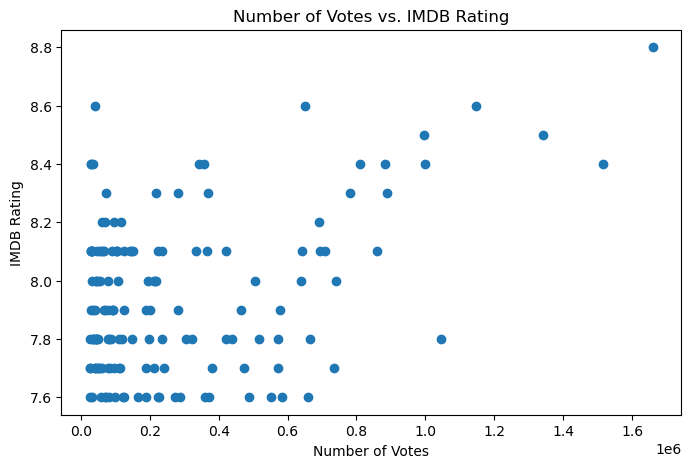

In [78]:
plt.figure(figsize=(8, 5))

plt.scatter(
    random_sample["No_of_Votes"],
    random_sample["IMDB_Rating"]
)

plt.xlabel("Number of Votes")
plt.ylabel("IMDB Rating")
plt.title("Number of Votes vs. IMDB Rating")

plt.show()

## Box Plot

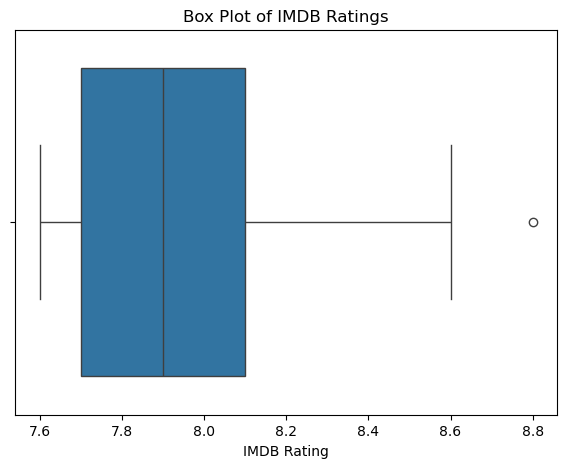

In [79]:
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.boxplot(x=random_sample["IMDB_Rating"])

plt.xlabel("IMDB Rating")
plt.title("Box Plot of IMDB Ratings")

plt.show()

## Histogram

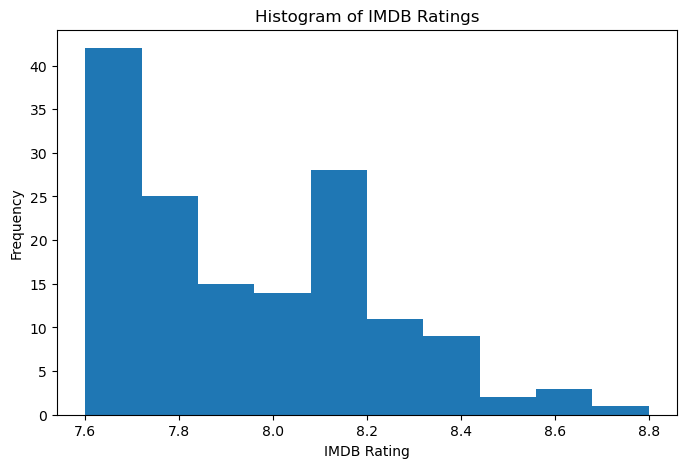

In [80]:
plt.figure(figsize=(8, 5))

plt.hist(
    random_sample["IMDB_Rating"],
    bins=10
)

plt.xlabel("IMDB Rating")
plt.ylabel("Frequency")
plt.title("Histogram of IMDB Ratings")

plt.show()

## Heat Map

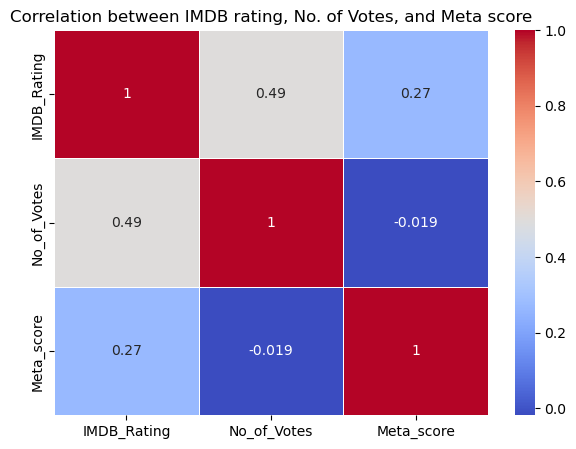

In [81]:
numerical_data = data[
    ["IMDB_Rating", "No_of_Votes", "Meta_score"]
]

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation between IMDB rating, No. of Votes, and Meta score")
plt.show()

# Hypothesis Test

## Pearson Correlation

In [82]:
from scipy.stats import pearsonr

random_sample = data.sample(n=150, random_state=42)

data = random_sample[["No_of_Votes", "IMDB_Rating"]].dropna()

votes = data["No_of_Votes"]
ratings = data["IMDB_Rating"]

r_value, p_value = pearsonr(votes, ratings)

degrees_of_freedom = len(data) - 2

print("Pearson Correlation Test Results:")
print(f"Pearson Correlation Coefficient (r): {r_value:.4f}")
print(f"P-Value: {p_value:.4f}")
print(f"Degrees of Freedom: {degrees_of_freedom}")

if p_value < 0.05:
    print("\nConclusion: Since the p-value is less than 0.05, we reject the null hypothesis.")
    print ("There is a statistically significant linear correlation between No_of_Votes and IMDB_Rating.")
else:
    print("\nConclusion: Since the p-value is greater than 0.05, we fail to reject the null hypothesis.")
    print("There is no statistically significant linear correlation between No_of_Votes and IMDB_Rating.")

Pearson Correlation Test Results:
Pearson Correlation Coefficient (r): 0.3935
P-Value: 0.0000
Degrees of Freedom: 148

Conclusion: Since the p-value is less than 0.05, we reject the null hypothesis.
There is a statistically significant linear correlation between No_of_Votes and IMDB_Rating.


## Spearman Correlation

In [83]:
from scipy.stats import spearmanr


random_sample = data.sample(n=150, random_state=42)

data = random_sample[["No_of_Votes", "IMDB_Rating"]]

r, p_value = spearmanr(
    data["No_of_Votes"],
    data["IMDB_Rating"]
)

degrees_of_freedom = len(data) - 2

print("Spearman's Correlation Test Results:")
print(f"Spearman's Correlation Coefficient (r): {r:.4f}")
print(f"P-Value: {p_value:.4f}")
print(f"Degrees of Freedom: {degrees_of_freedom}")

if p_value < 0.05:
    print("\nConclusion: Since the p-value is less than 0.05, we reject the null hypothesis.") 
    print("There is a statistically significant correlation between No_of_Votes and IMDB_Rating.")
else:
    print("\nConclusion: Since the p-value is greater than 0.05, we fail to reject the null hypothesis.") 
    print("There is no statistically significant correlation between No_of_Votes and IMDB_Rating.")

Spearman's Correlation Test Results:
Spearman's Correlation Coefficient (r): 0.1335
P-Value: 0.1035
Degrees of Freedom: 148

Conclusion: Since the p-value is greater than 0.05, we fail to reject the null hypothesis.
There is no statistically significant correlation between No_of_Votes and IMDB_Rating.


## One Sample T-test

In [84]:
import scipy
scipy.stats.ttest_1samp(random_sample["IMDB_Rating"], 8)

TtestResult(statistic=np.float64(-2.570261349007528), pvalue=np.float64(0.011142764335307358), df=np.int64(149))